#### **Setup & Data Loading**

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Load datasets
DATA_PATH = "../data/raw"
sales_lines = pd.read_csv(f"{DATA_PATH}/d365_sales_lines.csv")
item_master = pd.read_csv(f"{DATA_PATH}/d365_item_master.csv")
invoices = pd.read_csv(f"{DATA_PATH}/carrier_freight_invoices.csv")

print("-- Data Loaded Successfully --")
print(f"Sales Lines: {sales_lines.shape}")
print(f"Item Master: {item_master.shape}")
print(f"Carrier Invoices: {invoices.shape}")
invoices.head(3)

-- Data Loaded Successfully --
Sales Lines: (1000, 19)
Item Master: (180, 11)
Carrier Invoices: (1000, 12)


,Invoice_No,Airway_Bill_No,Document_No_,Carrier_Code,Billed_Weight_KG,Actual_Chargeable_Weight_KG,Contracted_Rate_AED,Billed_Amount_AED,Variance_AED,Surcharge_Description,Anomaly_Flag,Anomaly_Type
0,INV-CARRIER-40000,AWB-49283302,SO-DXB-30001,DHL Express,1079.0,1079.0,21040.50,21470.17,429.67,Uncontracted Peak Season Handling Surcharge,True,Unagreed_Surcharge
1,INV-CARRIER-40001,AWB-45907973,SO-DXB-30002,DHL Express,27.0,22.5,438.75,525.99,87.24,Standard Fuel & Security Surcharge,True,Weight_Overcharge
2,INV-CARRIER-40002,AWB-82668051,SO-DXB-30003,DHL Express,180.0,180.0,3510.00,3510.00,0.00,Standard Fuel & Security Surcharge,False,NaN


#### **Chargeable Weight Validation Engine**

In [6]:
# Merge sales and item master to get unit volumes and weights
merged_df = sales_lines.merge(item_master, left_on="Item_No_", right_on="No_")

# Calculate expected volumetric weight (Industry standard dim factor: 5000 cm3/kg or m3 equivalent)
merged_df['Calculated_Actual_Weight_KG'] = merged_df['Quantity_Shipped'] * merged_df['Net_Weight_KG']
merged_df['Calculated_Volumetric_Weight_KG'] = merged_df['Quantity_Shipped'] * (merged_df['Unit_Volume_M3'] * 5000)
merged_df['Expected_Chargeable_Weight'] = np.maximum(
    merged_df['Calculated_Actual_Weight_KG'], 
    merged_df['Calculated_Volumetric_Weight_KG']
)

print("-- Chargeable Weight Model Sample ---")
merged_df[['Document_No_', 'Quantity_Shipped', 'Calculated_Actual_Weight_KG', 'Calculated_Volumetric_Weight_KG', 'Expected_Chargeable_Weight']].head(5)

-- Chargeable Weight Model Sample ---


,Document_No_,Quantity_Shipped,Calculated_Actual_Weight_KG,Calculated_Volumetric_Weight_KG,Expected_Chargeable_Weight
0,SO-DXB-30001,166,167.66,1079.0,1079.0
1,SO-DXB-30002,1,1.98,22.5,22.5
2,SO-DXB-30003,8,30.80,180.0,180.0
3,SO-DXB-30004,9,5.13,67.5,67.5
4,SO-DXB-30005,83,331.17,2116.5,2116.5


#### **Carrier Rate Card Audit & Variance Analysis**

In [7]:
# Merge invoices with expected calculations
audit_df = invoices.merge(merged_df[['Document_No_', 'Expected_Chargeable_Weight']], on="Document_No_", how="left")

# Re-calculate contracted rate based on audit logic (19.5 AED/kg base rate)
BASE_RATE_AED = 19.5
audit_df['Audited_Base_Charge'] = audit_df['Expected_Chargeable_Weight'] * BASE_RATE_AED

# Compute audited variance
audit_df['Audit_Discrepancy_AED'] = audit_df['Billed_Amount_AED'] - audit_df['Audited_Base_Charge']

# Summarize findings by Anomaly Type
anomaly_summary = audit_df.groupby('Anomaly_Type').agg(
    Total_Incidents=('Invoice_No', 'count'),
    Total_Overbilling_AED=('Audit_Discrepancy_AED', lambda x: x[x > 0].sum()),
    Avg_Discrepancy_AED=('Audit_Discrepancy_AED', 'mean')
).round(2).reset_index()

print("-- Carrier Invoice Audit Summary by Exception Type --")
display(anomaly_summary)

-- Carrier Invoice Audit Summary by Exception Type --


,Anomaly_Type,Total_Incidents,Total_Overbilling_AED,Avg_Discrepancy_AED
0,Duplicate_Line,23,256922.25,11170.53
1,Unagreed_Surcharge,61,21854.61,358.27
2,Weight_Overcharge,85,267352.10,3145.32


#### **Recoverable Cost Leakage Visualization**

C:\Users\tohiba\AppData\Local\Temp\ipykernel_9700\1775168058.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


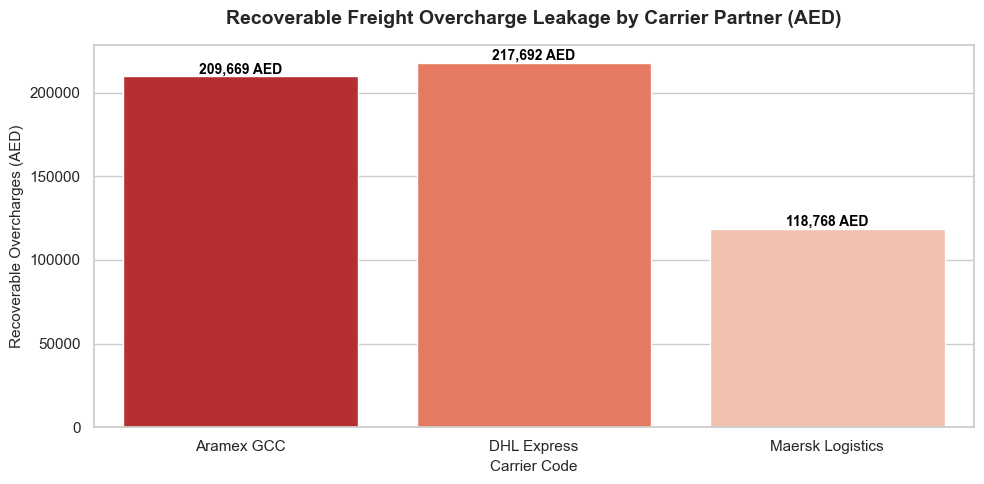

In [8]:
# Aggregate financial leakage by carrier
carrier_leakage = audit_df.groupby('Carrier_Code').agg(
    Total_Billed_AED=('Billed_Amount_AED', 'sum'),
    Recoverable_Leakage_AED=('Audit_Discrepancy_AED', lambda x: x[x > 0].sum())
).reset_index()

carrier_leakage['Leakage_Pct'] = (carrier_leakage['Recoverable_Leakage_AED'] / carrier_leakage['Total_Billed_AED']) * 100

# Plotting
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=carrier_leakage,
    x='Carrier_Code',
    y='Recoverable_Leakage_AED',
    palette='Reds_r'
)
plt.title('Recoverable Freight Overcharge Leakage by Carrier Partner (AED)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Carrier Code', fontsize=11)
plt.ylabel('Recoverable Overcharges (AED)', fontsize=11)

for p in ax.patches:
    ax.annotate(f"{p.get_height():,.0f} AED", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10, color='black', fontweight='bold')

plt.tight_layout()
plt.show()